# Projeto 05 — Credit Risk Model Stability
## 01 · Entendimento dos dados

**Objetivo deste notebook.** Antes de criar qualquer feature, responder:

1. Quem é a população (`train_base`)? Quantos casos, em que período, com que taxa de default?
2. O volume e a taxa de default mudam com o tempo? Há períodos atípicos?
3. Que fontes de dados existem, em que granularidade, e quais merecem ser exploradas?
4. Que cuidados cada fonte exige antes de entrar na Master Table?

Nenhum modelo é treinado aqui (a Semana 1 é só dados). As decisões tomadas a partir do que se vê
estão resumidas na seção 8 e são executadas no notebook `02_feature_engineering.ipynb`.

**Regra de uso dos dados neste projeto**

| Informação | De onde vem |
|---|---|
| Estrutura: linhas, `case_id`, datas, volume por mês, tamanho das tabelas | base inteira |
| Tudo o que envolve o `target` (taxa de default, IV) | **só TRAIN** |
| Missing, cobertura e distribuição de colunas usadas para decidir | **só TRAIN** |
| Regras de cálculo das features | fórmulas fixas, iguais para TRAIN, TEST e OOT |

Do OOT (2020-07 a 2020-10) só se lê quantos casos existem por mês. O target e as features desses
meses ficam fechados até a avaliação final da Semana 2.

## 0. Preparação

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # o notebook roda a partir de notebooks/

import matplotlib
import pandas as pd
import polars as pl
import polars.selectors as cs

from src import audit, plots
from src.catalog import source_notes_frame
from src.config import (
    CASE_ID, DATE_DECISION, FIGURES_DIR, MONTH, OOT, OOT_MONTHS, RANDOM_STATE, SOURCE_INVENTORY_PATH, SPLIT,
    TARGET, TEST, TEST_SIZE, TRAIN, WEEK_NUM,
)
from src.data import SOURCES, load_base, load_feature_definitions, scan_source
from src.split import assign_split

plots.apply_style()
pd.set_option("display.max_columns", 50, "display.max_colwidth", 120, "display.width", 200)
print(f"Python {sys.version.split()[0]} | polars {pl.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

Python 3.11.9 | polars 2.0.0 | pandas 3.0.5 | matplotlib 3.11.1


## 1. A população: `train_base`

`train_base` é a espinha dorsal: uma linha por caso de crédito, com a data da decisão e o target.
Tudo o que vier das outras tabelas será anexado a ela por LEFT JOIN, então o primeiro passo é
confirmar que ela tem mesmo uma linha por `case_id`.

In [2]:
base = load_base()
display(base.head(3).to_pandas())

first_day = base[DATE_DECISION].min()
week_from_date = (pl.col(DATE_DECISION) - first_day).dt.total_days() // 7
month_from_date = pl.col(DATE_DECISION).dt.year() * 100 + pl.col(DATE_DECISION).dt.month()
structure = pd.Series({
    "linhas": base.height,
    "case_id distintos": base[CASE_ID].n_unique(),
    "valores nulos (todas as colunas)": sum(base.null_count().row(0)),
    "primeira decisão": first_day,
    "última decisão": base[DATE_DECISION].max(),
    "dias com decisão / dias do período": f"{base[DATE_DECISION].n_unique()} / {(base[DATE_DECISION].max() - first_day).days + 1}",
    "meses (MONTH)": base[MONTH].n_unique(),
    "semanas (WEEK_NUM)": f"{base[WEEK_NUM].min()} a {base[WEEK_NUM].max()}",
    "linhas em que MONTH difere do mês de date_decision": base.filter(pl.col(MONTH) != month_from_date).height,
    "linhas em que WEEK_NUM difere de (dias desde a 1ª decisão) // 7": base.filter(pl.col(WEEK_NUM) != week_from_date).height,
}, name="train_base")
display(structure.to_frame())

,case_id,date_decision,MONTH,WEEK_NUM,target
0,0,2019-01-03,201901,0,0
1,1,2019-01-03,201901,0,0
2,2,2019-01-04,201901,0,0


,train_base
linhas,1526659
case_id distintos,1526659
valores nulos (todas as colunas),0
primeira decisão,2019-01-01
última decisão,2020-10-05
dias com decisão / dias do período,644 / 644
meses (MONTH),22
semanas (WEEK_NUM),0 a 91
linhas em que MONTH difere do mês de date_decision,0
linhas em que WEEK_NUM difere de (dias desde a 1ª decisão) // 7,0


**Leitura.**

- 1.526.659 casos e 1.526.659 `case_id` distintos: a granularidade é **1 `case_id` = 1 linha**, sem nulos.
- O período vai de 2019-01-01 a 2020-10-05, sem nenhum dia vazio: 22 meses e 92 semanas.
- `MONTH` é exatamente o ano-mês de `date_decision`, e `WEEK_NUM` é o número de semanas completas
  desde 2019-01-01. Não trazem informação além da data, só servem para agregar.

## 2. TRAIN, TEST e OOT, definidos antes de olhar o target

O enunciado fixa o **OOT** nos meses 2020-07 a 2020-10 e manda dividir o restante ao acaso.
A divisão é feita já aqui, com a `train_base` apenas, porque todas as análises seguintes que
usam o target precisam saber quais linhas podem ser olhadas.

- **OOT**: `MONTH` em {2020-07, 2020-08, 2020-09, 2020-10}.
- **TRAIN / TEST**: casos anteriores a 2020-07, divididos 80% / 20% ao acaso, estratificados pelo
  target, com semente fixa (`RANDOM_STATE = 42`). Com mais de 1,3 milhão de casos, 20% já dão um
  TEST com milhares de defaults, e 80% deixam o máximo de dados para as features e o modelo.

A regra mora em `src/split.py` e o resultado vira a coluna `split` da Master Table.

In [3]:
base = assign_split(base)
train = base.filter(pl.col(SPLIT) == TRAIN)

split_summary = (
    base.group_by(SPLIT)
    .agg(
        pl.len().alias("casos"),
        pl.col(MONTH).min().alias("primeiro mês"),
        pl.col(MONTH).max().alias("último mês"),
        pl.col(MONTH).n_unique().alias("meses"),
    )
    .with_columns((pl.col("casos") / base.height).round(4).alias("parcela"))
    .to_pandas()
    .set_index(SPLIT)
    .loc[[TRAIN, TEST, OOT]]
)
display(split_summary)
print(f"TEST / (TRAIN + TEST) = {split_summary.loc[TEST, 'casos'] / split_summary.loc[[TRAIN, TEST], 'casos'].sum():.4f}"
      f" (alvo: {TEST_SIZE}) | semente: {RANDOM_STATE} | meses do OOT: {OOT_MONTHS}")

,casos,primeiro mês,último mês,meses,parcela
split,,,,,
TRAIN,1101135,201901,202006,18,0.7213
TEST,275284,201901,202006,18,0.1803
OOT,150240,202007,202010,4,0.0984


TEST / (TRAIN + TEST) = 0.2000 (alvo: 0.2) | semente: 42 | meses do OOT: (202007, 202008, 202009, 202010)


O OOT tem 150.240 casos (9,8% da base), e outubro de 2020 só tem os cinco primeiros dias do mês.
Daqui em diante, **tudo o que envolve o target usa só o TRAIN**. A taxa de default do TEST não
precisa ser olhada: por construção (estratificação), ela é igual à do TRAIN.

## 3. Volume e taxa de default ao longo do tempo

O desafio do projeto é a estabilidade temporal, então a primeira pergunta é se a própria
população é estável. O volume é mostrado para todos os meses (é só uma contagem de linhas);
a taxa de default, só para o TRAIN.

TRAIN: 1,101,135 casos, 35,855 defaults, taxa de default 3.26% (1 default para cada 30 bons pagadores)


,n,defaults,default_rate,ci_low,ci_high,casos_no_mes_todos_os_splits
MONTH,,,,,,
201901,"60,691","1,567",2.58%,2.46%,2.71%,"75,529"
201902,"50,260","1,380",2.75%,2.61%,2.89%,"63,064"
201903,"55,318","1,460",2.64%,2.51%,2.78%,"69,147"
201904,"57,677","1,726",2.99%,2.86%,3.14%,"72,012"
201905,"51,608","1,706",3.31%,3.15%,3.46%,"64,594"
201906,"75,513","1,943",2.57%,2.46%,2.69%,"94,398"
201907,"77,918","2,125",2.73%,2.61%,2.84%,"97,566"
201908,"79,001","2,116",2.68%,2.57%,2.79%,"98,741"
201909,"78,931","2,681",3.40%,3.27%,3.53%,"98,706"


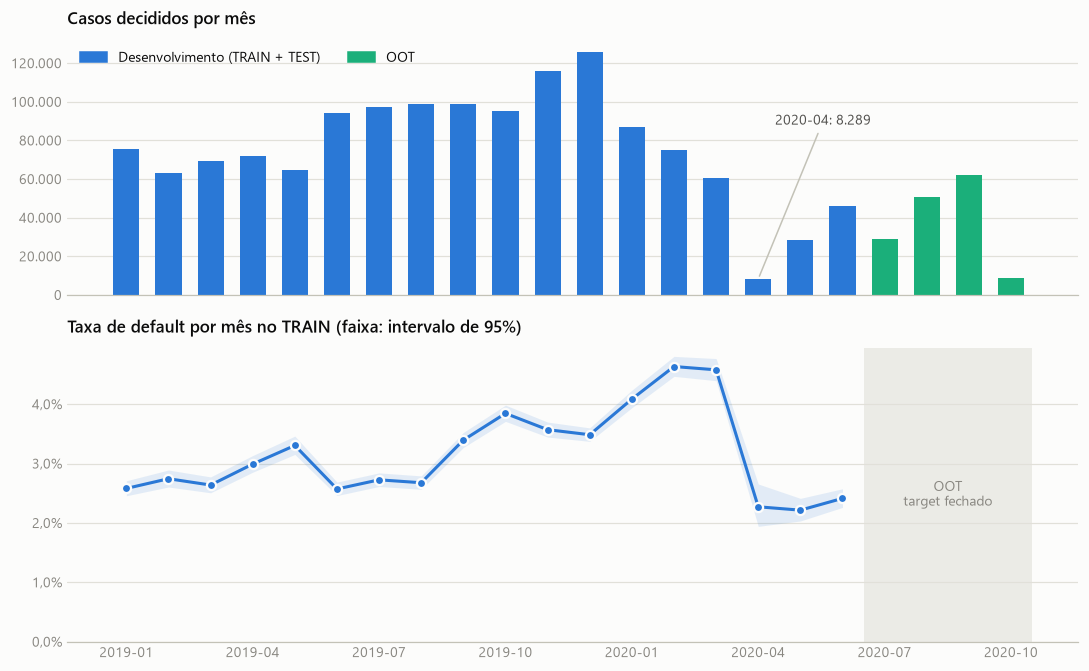

In [4]:
volume = base.group_by(MONTH).agg(pl.len().alias("n")).sort(MONTH).to_pandas().set_index(MONTH)
volume["is_oot"] = volume.index.isin(OOT_MONTHS)
monthly_rate = audit.default_rate_by(train, MONTH, TARGET)
overall_rate = train[TARGET].mean()

fig = plots.plot_population(volume, monthly_rate)
plots.save_figure(fig, FIGURES_DIR / "population_over_time.png")

print(f"TRAIN: {train.height:,} casos, {train[TARGET].sum():,} defaults, taxa de default {overall_rate:.2%}"
      f" (1 default para cada {(1 - overall_rate) / overall_rate:.0f} bons pagadores)")
display(monthly_rate.assign(casos_no_mes_todos_os_splits=volume["n"]).style.format(
    {"default_rate": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}", "n": "{:,}", "defaults": "{:,}",
     "casos_no_mes_todos_os_splits": "{:,}"}))

Taxa semanal no TRAIN: de 2.04% (semana 70) a 5.24% (semana 62); semanas com menos de 2.000 casos no TRAIN: 5


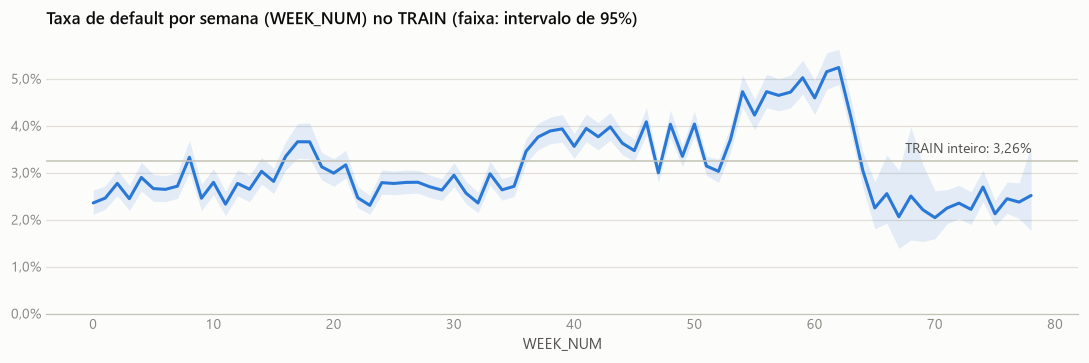

In [5]:
weekly_rate = audit.default_rate_by(train, WEEK_NUM, TARGET)
fig = plots.plot_weekly_default_rate(weekly_rate, overall_rate)
plots.save_figure(fig, FIGURES_DIR / "default_rate_by_week.png")

extremes = weekly_rate["default_rate"].agg(["min", "idxmin", "max", "idxmax"])
print(f"Taxa semanal no TRAIN: de {extremes['min']:.2%} (semana {extremes['idxmin']:.0f}) a {extremes['max']:.2%}"
      f" (semana {extremes['idxmax']:.0f}); semanas com menos de 2.000 casos no TRAIN: {(weekly_rate['n'] < 2000).sum()}")

**Respostas às perguntas da Etapa 1.**

- **Existe desbalanceamento?** Sim, forte: 3,26% de default no TRAIN, cerca de 1 mau pagador para
  30 bons. Accuracy não serve como métrica; ROC AUC (a métrica do projeto), PR AUC e KS medem
  ordenação e não se deixam enganar pela classe majoritária.
- **O volume muda com o tempo?** Muito. Fica entre 63 mil e 76 mil casos por mês até maio de 2019,
  sobe para perto de 100 mil no segundo semestre e chega a 126 mil em dezembro de 2019; cai ao
  longo do primeiro trimestre de 2020 e **desaba em abril de 2020 (8.289 casos)**, voltando só em
  parte até o OOT. A queda coincide com o início da pandemia de covid-19 (interpretação minha: os
  dados não trazem a causa).
- **A taxa de default muda com o tempo?** Sim, e de forma não monótona: fica entre 2,6% e 3,3% até
  agosto de 2019, sobe a partir de setembro (3,4%) até 4,6% em fevereiro de 2020 e cai para
  2,2%–2,4% entre abril e junho de 2020. Os intervalos de confiança mensais desses patamares não
  se sobrepõem, ou seja, não é ruído amostral.
- **Há períodos muito diferentes?** Dois: (i) janeiro a março de 2020, com a maior inadimplência;
  (ii) abril a junho de 2020, com volume muito menor e inadimplência baixa, o que é compatível com
  uma concessão mais restrita no período. O OOT vem logo depois desse segundo regime.

**O que isso muda no projeto.**

1. A taxa base se desloca no tempo. Qualquer feature cuja *disponibilidade* também mude no tempo
   pode "aprender o mês" em vez de aprender risco. Por isso a seção 5 olha a cobertura mês a mês.
2. O OOT sucede um período atípico: a queda de desempenho TEST → OOT é um risco real e precisa
   ser medida por mês e por semana na Semana 2 (o gráfico semanal mostra o quanto a taxa oscila).
3. O split aleatório TRAIN/TEST mistura todos os meses e não detecta esse efeito; só o OOT detecta.

## 4. Mapa das fontes

Além da `train_base` há 16 famílias de tabelas, em três granularidades:

- **depth 0**: uma linha por caso → entra por join direto;
- **depth 1**: várias linhas por caso, indexadas por `num_group1` → precisa de agregação;
- **depth 2**: indexadas por `num_group1` e `num_group2` → agregação em dois níveis.

O inventário abaixo conta linhas e casos de cada fonte (contagem estrutural, base inteira) e
registra o que a fonte representa, a hipótese de negócio e a decisão. As descrições das colunas
vêm de `feature_definitions.csv`.

In [6]:
definitions = load_feature_definitions()
print(f"feature_definitions.csv: {len(definitions)} colunas descritas. Exemplo: annuity_780A = {definitions['annuity_780A']!r}")

inventory = audit.source_inventory(base).merge(source_notes_frame(), on="fonte")
SOURCE_INVENTORY_PATH.parent.mkdir(parents=True, exist_ok=True)
inventory.to_csv(SOURCE_INVENTORY_PATH, index=False)
display(inventory.style.format({"linhas": "{:,}", "cases_unicos": "{:,}", "cobertura": "{:.1%}",
                                "registros_por_case_mediana": "{:.0f}"}).hide(axis="index"))

feature_definitions.csv: 465 colunas descritas. Exemplo: annuity_780A = 'Monthly annuity amount.'


fonte,depth,origem,linhas,cases_unicos,cobertura,n_colunas,registros_por_case_mediana,registros_por_case_max,o_que_representa,hipotese_de_negocio,estrategia,decisao
static_0,0,interna,"1,526,659","1,526,659",100.0%,168,1,1,"Pedido em análise e resumo, feito pelo credor, do comportamento do cliente em contratos anteriores",Quem atrasou parcelas com o próprio credor tende a atrasar de novo; pedidos e recusas recentes indicam busca por crédito,join direto + seleção de colunas,usar
static_cb_0,0,externa,"1,500,476","1,500,476",98.3%,53,1,1,Resumo externo: consultas ao bureau e deduções fiscais,Muitas consultas recentes ao bureau indicam busca intensa por crédito,join direto + seleção de colunas,usar (consultas ao bureau)
applprev_1,1,interna,"6,525,979","1,221,522",80.0%,41,4,20,Pedidos anteriores do cliente ao credor (os 20 mais recentes),"Recusas, atrasos e pedidos recentes antecipam risco; relacionamento longo e sem atraso reduz",agregação por case_id com corte na data de criação,usar
person_1,1,interna,"2,973,991","1,526,659",100.0%,37,1,10,"Pessoas do pedido: a linha 0 é o solicitante, as demais são contatos","Idade, tipo de renda e renda descrevem a estabilidade financeira do solicitante",filtro num_group1 = 0 + join,usar (só o solicitante)
other_1,1,interna,"51,109","51,109",3.3%,7,1,1,Entradas e saídas de conta e depósito,Fluxo de caixa indica capacidade de pagamento,-,não usar: só existe a partir de 2020-01 e cobre cerca de 3% dos casos
deposit_1,1,interna,"145,086","105,111",6.9%,5,1,65,Depósitos do cliente no credor,Ter reserva financeira no credor reduz o risco,-,não usar: cobre cerca de 7% dos casos e o indicador de presença quase não separa
debitcard_1,1,interna,"157,302","111,772",7.3%,6,1,66,Cartões de débito do cliente no credor,Movimentação de conta indica renda e relacionamento,-,não usar: cobre cerca de 7% dos casos e o indicador de presença quase não separa
credit_bureau_a_1,1,externa,"15,940,537","1,386,273",90.8%,79,10,529,"Contratos do cliente em outras instituições (bureau A), ativos e encerrados","Atraso em outros credores, crédito recém-aberto e histórico curto elevam o risco; complementa o histórico interno quando ele é pequeno","agregação por case_id, ativos e encerrados em separado",usar
credit_bureau_b_1,1,externa,"85,791","36,500",2.4%,45,2,21,Contratos do cliente no bureau B,Mesma do bureau A,-,não usar: cobre cerca de 2% dos casos
tax_registry_a_1,1,externa,"3,275,770","457,934",30.0%,5,6,99,Deduções fiscais por empregador (fornecedor A),Deduções regulares indicam emprego formal e renda estável,agregação unificada dos três fornecedores,usar (unificada)


**Leitura.**

- As duas tabelas `static` e a `person_1` cobrem praticamente todos os casos. O histórico interno
  de pedidos (`applprev_1`) cobre 80%, e o bureau A (`credit_bureau_a_1/2`) 91%: são as fontes com
  hipótese de risco mais direta (comportamento de pagamento) e cobertura alta.
- `credit_bureau_a_2` tem 188 milhões de linhas (mediana de 96 por caso): só entra com uma
  agregação desenhada para uma hipótese específica (atraso recente), não "tudo contra tudo".
- Bureau B, depósitos, cartão de débito e `other_1` cobrem de 2% a 7% dos casos. Não entram:
  um dado ausente em mais de 90% da população pouco ajuda e ainda cria dependência de uma fonte
  rara. `applprev_2` e `person_2` ficam fora por falta de hipótese de risco.
- As três tabelas de registro fiscal têm cobertura parcial (10% a 32% cada). A seção 5 mostra
  por quê.

## 5. Cobertura das fontes ao longo do tempo (TRAIN)

Para cada mês, que parcela dos casos do TRAIN tem pelo menos um registro em cada fonte? Uma
fonte que aparece ou desaparece no meio do período gera features instáveis por construção.

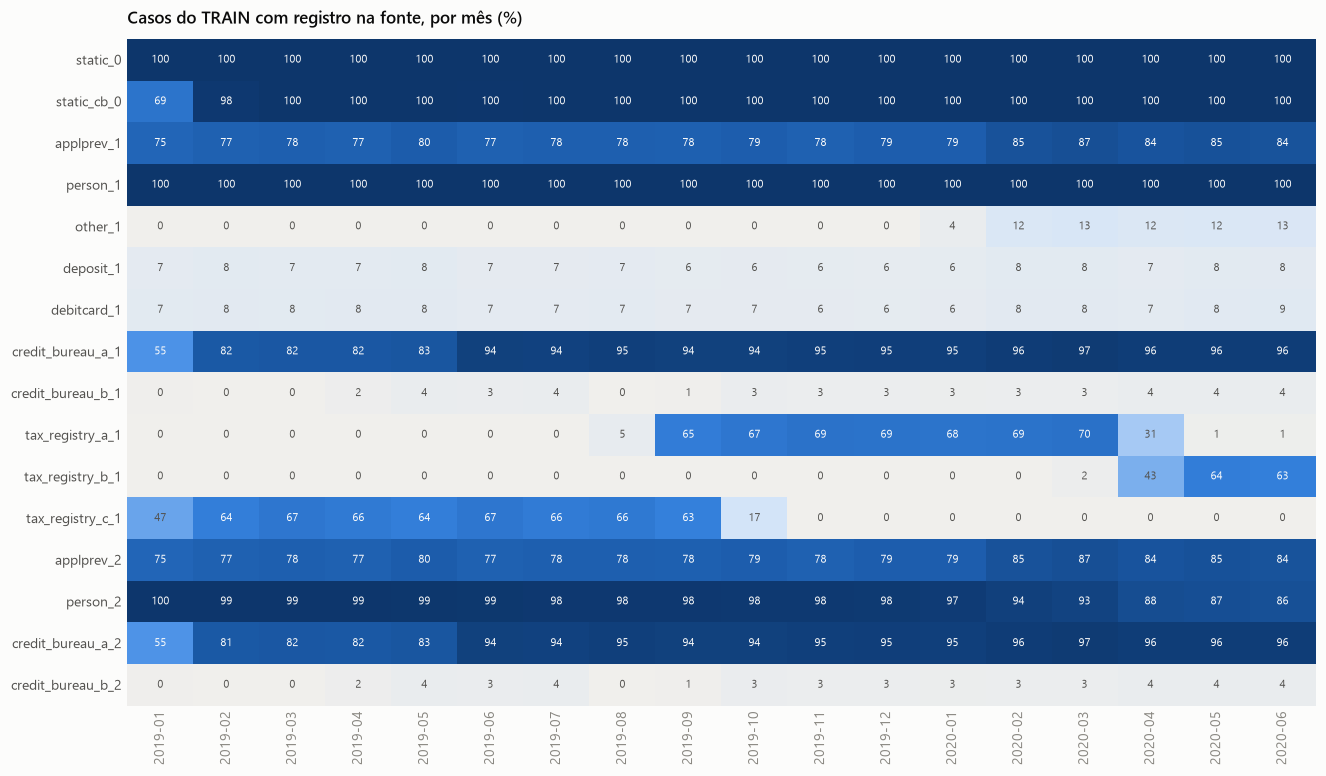

In [7]:
coverage = audit.coverage_by_month(train)
fig = plots.plot_share_heatmap(coverage[list(SOURCES)].T, "Casos do TRAIN com registro na fonte, por mês (%)")
plots.save_figure(fig, FIGURES_DIR / "source_coverage_by_month.png")

**Leitura.** A cobertura está longe de ser constante, e isso é o principal achado desta etapa:

- **Registro fiscal: três fornecedores que se revezam.** O fornecedor C cobre cerca de 65% dos
  casos de fevereiro a setembro de 2019 (47% em janeiro), cai para 17% em outubro e some; o A
  começa em agosto/setembro de 2019 e vai até abril de 2020; o B entra em abril de 2020 e passa a
  cobrir cerca de 64%. Uma feature feita com um só fornecedor "liga e desliga" conforme o mês. A
  única forma defensável de usar essa informação é **unificar os três** (seção 2.6 do notebook 02).
- **Bureau A entra em rampa.** A cobertura é de 55% em janeiro de 2019, 82%–83% de fevereiro a
  maio e 94% ou mais a partir de junho de 2019; `static_cb_0` (resumo do bureau) tem 69% em
  janeiro. Os primeiros cinco meses do TRAIN têm, portanto, menos informação externa que os demais.
- **`other_1` só existe a partir de 2020.** Mais um motivo para não usá-la.
- **Histórico interno é estável**, com uma mudança de patamar em fevereiro de 2020 (`applprev_1`
  passa de 79% para 85%): a carteira passa a ter mais clientes que já tinham pedido crédito antes.

Consequência: a disponibilidade de cada feature será conferida mês a mês antes de ela entrar na
Master Table, e fontes ou colunas que nascem ou morrem dentro do período serão evitadas.

## 6. Qualidade das colunas nas fontes priorizadas (TRAIN)

Para as fontes que vão ser exploradas: quantas colunas são constantes, quase vazias (95% ou mais
de ausentes) ou mudam de regime (0% de preenchimento em algum mês do TRAIN e mais de 5% em outro)?
Nas colunas categóricas mascaradas (sufixo `M`), o código `a55475b1` é o marcador de valor ausente
usado pelos organizadores e é contado como ausente. De `credit_bureau_a_2` entram só as 10
colunas numéricas (pagamentos e garantias).

In [8]:
PRIORITISED = ["static_0", "static_cb_0", "person_1", "applprev_1", "credit_bureau_a_1", "credit_bureau_a_2",
               "tax_registry_a_1", "tax_registry_b_1", "tax_registry_c_1"]
train_months = train.select(CASE_ID, MONTH)

quality = {}
for name in PRIORITISED:
    records = scan_source(name)
    if name == "person_1":
        records = records.filter(pl.col("num_group1") == 0)  # só a linha do solicitante
    if name == "credit_bureau_a_2":
        records = records.select(CASE_ID, cs.float())  # as 6 colunas de texto (garantias, papéis) não têm uso previsto
    records = records.drop("num_group1", "num_group2", strict=False)
    quality[name] = audit.column_quality(records, train_months).assign(fonte=name)
quality = pd.concat(quality.values(), ignore_index=True)

quality_summary = quality.groupby("fonte", sort=False).agg(
    colunas=("coluna", "size"),
    constantes=("constante", "sum"),
    quase_vazias=("quase_vazia", "sum"),
    mudam_de_regime=("muda_de_regime", "sum"),
    missing_mediano=("missing", "median"),
)
display(quality_summary.style.format({"missing_mediano": "{:.1%}"}))

,colunas,constantes,quase_vazias,mudam_de_regime,missing_mediano
fonte,,,,,
static_0,167,12,11,27,30.5%
static_cb_0,52,5,26,18,95.3%
person_1,35,12,11,1,52.5%
applprev_1,39,0,7,2,46.1%
credit_bureau_a_1,77,0,10,32,83.3%
credit_bureau_a_2,10,0,2,4,63.4%
tax_registry_a_1,3,0,0,0,0.0%
tax_registry_b_1,3,0,0,0,0.0%
tax_registry_c_1,3,0,0,0,0.0%


In [9]:
flagged = quality[quality["muda_de_regime"]].copy()
flagged["descricao"] = flagged["coluna"].map(definitions)
print("Colunas de static_0 que mudam de regime no TRAIN (0% de preenchimento em algum mês):")
display(flagged.loc[flagged["fonte"] == "static_0", ["coluna", "missing", "preenchimento_max_mes", "descricao"]]
        .style.format({"missing": "{:.1%}", "preenchimento_max_mes": "{:.1%}"}).hide(axis="index"))

bureau_regime = flagged.loc[flagged["fonte"] == "credit_bureau_a_1", "descricao"]
print(f"credit_bureau_a_1: {len(bureau_regime)} colunas mudam de regime; "
      f"{bureau_regime.str.contains('closed|terminated', case=False).sum()} delas descrevem contratos encerrados (closed/terminated).")

Colunas de static_0 que mudam de regime no TRAIN (0% de preenchimento em algum mês):


coluna,missing,preenchimento_max_mes,descricao
amtinstpaidbefduel24m_4187115A,38.4%,77.6%,Number of instalments paid before due date in the last 24 months.
avgdbddpdlast3m_4187120P,63.0%,48.6%,Average days past or before due of payment during the last 3 months.
avgdbdtollast24m_4525197P,67.1%,68.0%,Average days of payment before due date within the last 24 months (with tolerance).
avglnamtstart24m_4525187A,89.5%,23.4%,Average loan amount in the last 24 months.
avgoutstandbalancel6m_4187114A,56.2%,58.1%,Average outstanding balance of applicant for the last 6 months.
avgpmtlast12m_4525200A,70.3%,62.0%,Average of payments made by the client in the last 12 months.
datelastinstal40dpd_247D,91.9%,12.3%,Date of last instalment that was more than 40 days past due (DPD).
dtlastpmtallstes_4499206D,66.4%,60.1%,Date of last payment made by the applicant.
lastrejectreasonclient_4145040M,65.2%,47.7%,Reason for the client's last loan rejection.
maxdbddpdtollast6m_4187119P,58.4%,54.0%,Maximum number of days past due in last 6 months. This predictor takes the value as a negative number when it represents days before due date.


credit_bureau_a_1: 32 colunas mudam de regime; 30 delas descrevem contratos encerrados (closed/terminated).


**Leitura.**

- `static_0` tem 167 colunas: 12 com um único valor observado, 11 quase vazias e **27 que mudam
  de regime**, quase todas variáveis que o credor passou a calcular no meio do período (0% de
  preenchimento em algum mês de 2019). Mesmo quando têm sinal, ficam na lista de colunas a evitar:
  há equivalentes disponíveis no período inteiro.
- Em `static_cb_0`, metade das 52 colunas é quase vazia e 18 mudam de regime: são as colunas de
  dedução fiscal, uma versão por fornecedor (o revezamento da seção 5).
- Em `person_1`, um terço das colunas só faz sentido para contatos e fica constante ou vazio na
  linha do solicitante.
- Em `credit_bureau_a_1`, 32 das 77 colunas mudam de regime, e quase todas descrevem contratos
  **encerrados**: há meses de 2019 em que o bureau simplesmente não envia esses contratos. Em
  `credit_bureau_a_2` acontece o mesmo com as 4 colunas de pagamentos de contratos encerrados.
  Isso afeta diretamente as agregações de bureau e é tratado na seção 2.4 do notebook 02.
- Nas tabelas de histórico, boa parte do missing é estrutural: cada linha descreve um contrato
  ativo e/ou um encerrado, e as colunas do outro tipo ficam vazias (seção 7).

A tabela completa por coluna fica na variável `quality`; as colunas escolhidas e as descartadas,
com o motivo, estão no catálogo de features do notebook 02.

## 7. Granularidade: por que não dá para fazer um merge direto

Três estruturas precisam ser entendidas antes de agregar.

In [10]:
train_ids = train.lazy().select(CASE_ID)

persons = scan_source("person_1").join(train_ids, on=CASE_ID).group_by("num_group1").agg(
    pl.len().alias("linhas"),
    pl.col("birth_259D").is_not_null().mean().alias("com data de nascimento"),
    pl.col("mainoccupationinc_384A").is_not_null().mean().alias("com renda"),
    pl.col("relationshiptoclient_415T").is_not_null().mean().alias("com parentesco"),
).sort("num_group1").collect()
print("person_1: o que cada num_group1 contém (TRAIN)")
display(persons.to_pandas().head(4).style.format({"linhas": "{:,}", "com data de nascimento": "{:.0%}",
                                                  "com renda": "{:.0%}", "com parentesco": "{:.0%}"}).hide(axis="index"))

applications = scan_source("applprev_1").join(train_ids, on=CASE_ID).group_by(CASE_ID).agg(
    pl.len().alias("pedidos"),
    (pl.col("creationdate_885D").sort_by("num_group1").diff().fill_null(pl.duration(days=0)) <= pl.duration(days=0)).all().alias("ordenado"),
).collect()
print(f"applprev_1: máximo de {applications['pedidos'].max()} pedidos por caso; "
      f"{(applications['pedidos'] == applications['pedidos'].max()).mean():.1%} dos casos com histórico estão nesse teto; "
      f"num_group1 crescente = pedido mais antigo em {applications['ordenado'].mean():.1%} dos casos.")

bureau = scan_source("credit_bureau_a_1").join(train_ids, on=CASE_ID).group_by(
    pl.col("dateofcredstart_739D").is_not_null().alias("tem contrato ativo na linha"),
    pl.col("dateofcredstart_181D").is_not_null().alias("tem contrato encerrado na linha"),
).agg(pl.len().alias("linhas")).sort("linhas", descending=True).collect(engine="streaming")
print("credit_bureau_a_1: o que cada linha carrega (TRAIN)")
display(bureau.to_pandas().assign(parcela=lambda table: table["linhas"] / table["linhas"].sum())
        .style.format({"linhas": "{:,}", "parcela": "{:.1%}"}).hide(axis="index"))

person_1: o que cada num_group1 contém (TRAIN)


num_group1,linhas,com data de nascimento,com renda,com parentesco
0,"1,101,135",100%,100%,0%
1,"549,388",0%,0%,76%
2,"377,948",0%,0%,43%
3,"143,731",0%,0%,2%


applprev_1: máximo de 20 pedidos por caso; 2.6% dos casos com histórico estão nesse teto; num_group1 crescente = pedido mais antigo em 100.0% dos casos.


credit_bureau_a_1: o que cada linha carrega (TRAIN)


tem contrato ativo na linha,tem contrato encerrado na linha,linhas,parcela
False,False,"6,175,169",54.2%
False,True,"3,297,938",29.0%
True,True,"1,269,254",11.1%
True,False,"642,739",5.6%


**Leitura.**

- **`person_1`**: a linha `num_group1 = 0` é o solicitante (100% com nascimento e renda); as demais
  são contatos e parentes (sem renda, com parentesco). Um `mean()` sobre todas as linhas misturaria
  o cliente com os contatos. A regra será **filtrar `num_group1 = 0`** e fazer o join.
- **`applprev_1`**: guarda no máximo os 20 pedidos mais recentes, do mais novo (`num_group1 = 0`)
  para o mais antigo. Contagens ficam truncadas em 20 para uma pequena parte dos clientes.
- **`credit_bureau_a_1`**: cada linha é um "zíper" de duas listas independentes: o i-ésimo contrato
  **ativo** (um conjunto de colunas) ao lado do i-ésimo contrato **encerrado** (outro conjunto).
  Mais da metade das linhas não tem nenhum dos dois (só carregam listas auxiliares). Contar linhas
  não é contar contratos; as agregações precisam tratar as duas listas em separado. O mesmo vale
  para os pagamentos em `credit_bureau_a_2`.

## 8. Conclusões e decisões para a engenharia de features

| O que os dados mostraram | Decisão |
|---|---|
| `train_base` tem 1 linha por `case_id`, sem nulos | é a espinha da Master Table; tudo entra por LEFT JOIN validado como 1:1 |
| Target raro (3,26%) | métricas de ordenação (ROC AUC, PR AUC, KS); nada de accuracy |
| Volume e default mudam de patamar várias vezes; o OOT sucede um período atípico | estabilidade medida por mês/semana; evitar features cuja disponibilidade muda no tempo |
| 16 fontes, mas só 6 famílias têm cobertura alta e hipótese clara | usar `static_0`, `static_cb_0`, `person_1`, `applprev_1`, bureau A (depth 1 e 2) e registro fiscal unificado |
| Bureau B, depósitos, débito e `other_1` cobrem de 2% a 7% | não usar |
| Três fornecedores de registro fiscal se revezam | nunca criar feature por fornecedor; unificar |
| Bureau A só atinge cobertura plena em 2019-06 e não envia contratos encerrados antes disso | conferir a disponibilidade mensal de cada feature de bureau; não calcular com dado parcial |
| Colunas constantes, quase vazias e que mudam de regime | ficam fora da seleção de colunas originais |
| `person_1` mistura solicitante e contatos; bureau A mistura duas listas por linha | filtrar o solicitante; agregar ativos e encerrados em separado |

Falta a pergunta mais importante da semana: **cada informação já existia em `date_decision`?**
Ela abre o notebook 02.